# Hidden network units - one simple notebook

**Paper:** Haehne et al., *Detecting Hidden Units and Network Size from Perceptible Dynamics*, Physical Review Letters **122**, 158301 (2019).

**Question:** If a network has `N` units but we measure only `n`, can we estimate `N` from several response experiments?

**Notation:**

| Symbol | Meaning |
|---|---|
| `N` | True number of units (unknown when analyzing data) |
| `n` | Number of observed units |
| `M` | Number of different response trials |
| `k` | Number of time points chosen from each trial |
| `T` | Detection matrix, shape `(k*n, M)` |

**Main idea:** Construct `T`, compute its singular values, and locate the **index** of the largest suitable logarithmic gap. Under suitable assumptions, this index estimates the number of network units.

This notebook is a **short, independent teaching example**, not the authors' original data or an exact numerical reproduction of their published figures. Figures 3 and 4 use simplified experimental protocols.

Run the cells from top to bottom. Only `numpy`, `scipy`, and `matplotlib` are needed.

## 1. Import the three libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.integrate import solve_ivp

## 2. Make the detection matrix (paper Eq. 6 and Eq. 10)

Input: `trials[experiment, time, observed_unit]`, a 3D array of shape `(M, time_samples, n)`.

For each experiment, stack the values from the selected `k` times. Each experiment becomes **one column** in `T`.

In [3]:
example

array([[[ 0,  1],
        [ 2,  3],
        [ 4,  5]],

       [[ 6,  7],
        [ 8,  9],
        [10, 11]],

       [[12, 13],
        [14, 15],
        [16, 17]]])

In [2]:
def make_T(trials, k, m=None, n=None):
    if m is None:
        m = trials.shape[0]
    if n is None:
        n = trials.shape[2]

    # Choose k equally spaced time positions.
    times = np.linspace(0, trials.shape[1] - 1, k, endpoint=False).astype(int)

    # Rows: time 1 (all n units), time 2 (all n units), ...
    # Columns: separate experiments.
    T = trials[:m, times, :n].transpose(1, 2, 0).reshape(k * n, m)
    return T

# Tiny example: M = 3 trials, 3 time samples, n = 2 observed units
example = np.arange(18).reshape(3, 3, 2)
print('Example T (k=2):')
print(make_T(example, k=2))

Example T (k=2):
[[ 0  6 12]
 [ 1  7 13]
 [ 2  8 14]
 [ 3  9 15]]


## 3. Estimate the network size with SVD (paper Eq. 9)

1. Compute the singular values of `T`.
2. Calculate the logarithmic gaps: $\Delta_j=\log(\sigma_j)-\log(\sigma_{j+1})$.
3. Pick the **index** `j` of the largest admissible gap, *not its height*.
4. Repeat with `n, n-1, ..., n-4` observed units and take the median (paper's safeguard).

The paper ignores candidate gap indices that equal `n, 2n, ...` or `n+1, 2n+1, ...`, using the current observed-unit count each time. The tiny numerical floor below prevents taking `log(0)`.

In [5]:
def estimate_size(trials, m):
    all_n = trials.shape[2]
    guesses = []

    for n in range(all_n, max(all_n - 5, 2), -1):
        k = int(np.ceil(m / n))
        if k > trials.shape[1]:
            continue

        T = make_T(trials, k, m, n)
        s = np.linalg.svd(T, compute_uv=False)
        floor = max(s[0] * 1e-14, 1e-300)  # numerical safeguard
        gaps = np.log(np.maximum(s[:-1], floor) / np.maximum(s[1:], floor))

        j = np.arange(1, len(s))  # gap AFTER singular value j
        allowed = (j >= n) & (j % n != 0) & (j % n != 1)
        if np.any(allowed):
            guesses.append(int(j[allowed][np.argmax(gaps[allowed])]))

    if not guesses:
        return None
    return int(np.rint(np.median(guesses)))

## 4. A linear network

This is an illustrative coupled system $\dot x=Ax$. `A` has negative diagonal entries (self-decay) and small off-diagonal interactions. We know the true size `N` because we generated the simulation. Then we pretend we observe only the first `n` units.

In [6]:
rng = np.random.default_rng(10)
N, n, M = 18, 11, 40

A = -np.diag(rng.uniform(0.3, 1.5, N))
A += 0.2 * rng.normal(size=(N, N)) / np.sqrt(N)
initial = rng.uniform(-1, 1, size=(N, M))
time = np.linspace(0, 2, 101)

# Simulate all M experiments for the same matrix A.
states = np.array([expm(A * t) @ initial for t in time])  # time, N, M
linear_trials = states[:, :n, :].transpose(2, 0, 1)    # M, time, n

print('Measured data shape:', linear_trials.shape)
print('Actual network size:', N)
print('Estimated size:', estimate_size(linear_trials, M))
print('Estimated hidden units:', estimate_size(linear_trials, M) - n)

Measured data shape: (40, 101, 11)
Actual network size: 18
Estimated size: 18
Estimated hidden units: 7


### singular values and number of trials

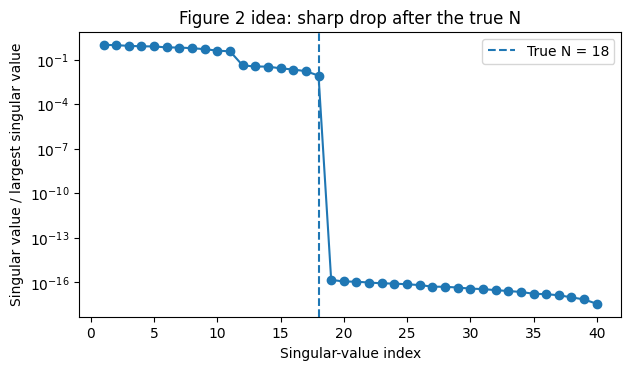

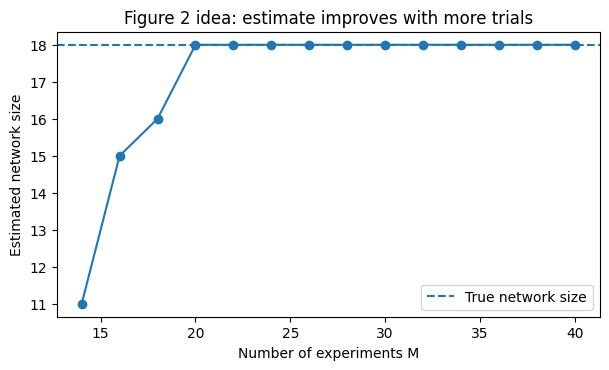

In [5]:
k = int(np.ceil(M / n))
T = make_T(linear_trials, k)
s = np.linalg.svd(T, compute_uv=False)

plt.figure(figsize=(7, 3.7))
plt.semilogy(np.arange(1, len(s) + 1), s / s[0], 'o-')
plt.axvline(N, linestyle='--', label=f'True N = {N}')
plt.xlabel('Singular-value index')
plt.ylabel('Singular value / largest singular value')
plt.title('Figure 2 idea: sharp drop after the true N')
plt.legend()
plt.show()

m_values = np.arange(n + 3, M + 1, 2)
size_values = [estimate_size(linear_trials, m) for m in m_values]
plt.figure(figsize=(7, 3.7))
plt.plot(m_values, size_values, 'o-')
plt.axhline(N, linestyle='--', label='True network size')
plt.xlabel('Number of experiments M')
plt.ylabel('Estimated network size')
plt.title('Figure 2 idea: estimate improves with more trials')
plt.legend()
plt.show()

## 5. Nonlinear example for Figure 2: Kuramoto oscillators

Each oscillator obeys $\dot\theta_i=\omega_i+c\sum_j W_{ij}\sin(\theta_j-\theta_i)$.

The system is nonlinear. We first allow the phases to settle near a phase-locked regime, add small perturbations, then subtract a **reference trial**. This produces the small response differences used by the detection method.

In [6]:
# Simple random directed connections: W[i, j] means j influences i.
def random_links(N, degree, rng, weighted=False):
    W = np.zeros((N, N))
    for i in range(N):
        choices = np.delete(np.arange(N), i)
        neighbors = rng.choice(choices, size=degree, replace=False)
        W[i, neighbors] = rng.uniform(0.2, 0.5, degree) if weighted else 1.0
    return W

rng = np.random.default_rng(7)
N, n, M = 18, 11, 40
W = random_links(N, 3, rng)
omega = rng.uniform(-0.1, 0.1, N)
c = 3.0

def one_phase(t, theta):
    return omega + c * np.sum(W * np.sin(theta[None, :] - theta[:, None]), axis=1)

reference = solve_ivp(one_phase, (0, 70), np.zeros(N)).y[:, -1]
initial = reference[:, None] + rng.uniform(-0.01, 0.01, (N, M + 1))

def all_phases(t, flat):
    x = flat.reshape(N, M + 1)
    coupling = np.sum(W[:, :, None] * np.sin(x[None] - x[:, None]), axis=1)
    return (omega[:, None] + c * coupling).ravel()

result = solve_ivp(all_phases, (0, 1), initial.ravel(),
                   t_eval=np.linspace(0, 1, 101), rtol=1e-9, atol=1e-11)
phases = result.y.reshape(N, M + 1, -1)
kuramoto_trials = (phases[:n, 1:] - phases[:n, :1]).transpose(1, 2, 0)
print('Kuramoto: actual N =', N, '| estimated N =', estimate_size(kuramoto_trials, M))

Kuramoto: actual N = 18 | estimated N = 18


## 6. Figure 3 idea: periodic and chaotic Rossler networks

A Rossler oscillator has **three internal coordinates** $(x,y,z)$. We perturb only its $x$ coordinate and measure the response difference in that coordinate. This simple experiment tests the observable subspace driven by those perturbations; the true full network state contains `3*N` coordinates.

**Important:** The published Figure 3 uses perturbations triggered by visits to a selected attractor region. Here, for clarity, all perturbations start near a single shared reference state. Therefore the plot is *Figure 3-inspired*, not an exact reproduction.

In [7]:
def rossler_trials(regime):
    rng = np.random.default_rng(7)
    N, n, M = 16, 11, 45
    W = random_links(N, 4, rng)
    L = np.diag(W.sum(axis=1)) - W
    a, b, c = (0.2, 1.7, 4.0) if regime == 'periodic' else (0.2, 0.2, 5.7)

    def one(t, s):
        x, y, z = s
        return [-y - z, x + a * y, b + z * (x - c)]

    center = solve_ivp(one, (0, 100), [1, 1, 1],
                       rtol=1e-10, atol=1e-12).y[:, -1]
    initial = np.broadcast_to(center[:, None, None], (3, N, M + 1)).copy()
    initial[0] += rng.uniform(-1e-4, 1e-4, (N, M + 1))

    def all_rossler(t, flat):
        x, y, z = flat.reshape(3, N, M + 1)
        return np.array([-y - z, x + a * y - L @ y, b + z * (x - c)]).ravel()

    result = solve_ivp(all_rossler, (0, 3), initial.ravel(),
                       t_eval=np.linspace(0, 3, 121), rtol=1e-10, atol=1e-12)
    x = result.y.reshape(3, N, M + 1, -1)[0, :n]
    differences = (x[:, 1:] - x[:, :1]).transpose(1, 2, 0)
    return differences

periodic = rossler_trials('periodic')
chaotic = rossler_trials('chaotic')
print('Periodic Rossler: true 16, estimated', estimate_size(periodic, 45))
print('Chaotic Rossler:  true 16, estimated', estimate_size(chaotic, 45))

Periodic Rossler: true 16, estimated 16
Chaotic Rossler:  true 16, estimated 16


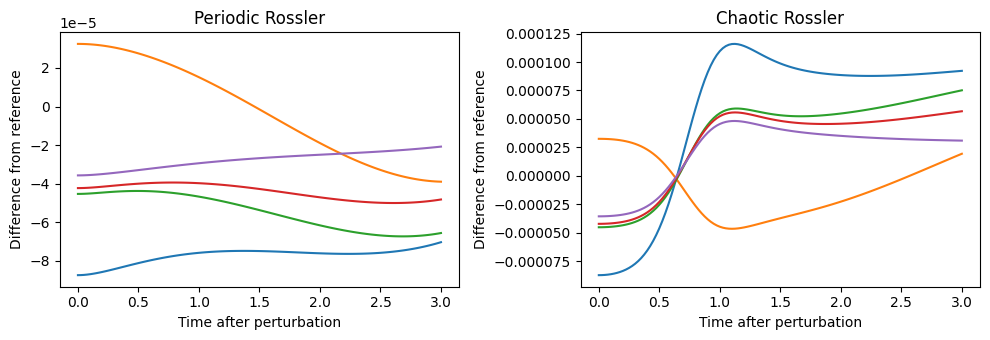

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, data, title in zip(axes, [periodic, chaotic],
                           ['Periodic Rossler', 'Chaotic Rossler']):
    for trial in range(5):
        ax.plot(np.linspace(0, 3, data.shape[1]), data[trial, :, 0])
    ax.set_title(title)
    ax.set_xlabel('Time after perturbation')
    ax.set_ylabel('Difference from reference')
plt.tight_layout()
plt.show()

## 7. Figure 4 idea: nonlinear Michaelis-Menten network

Use the simple biochemical model

$$\dot z_i=-z_i+\sum_j W_{ij}\frac{z_j}{1+z_j}.$$

Again, run many small perturbations from a shared reference and apply the **same** SVD estimator. The last plot adds **measurement noise** to illustrate a limitation. The paper's Figure 4 uses stochastic intrinsic dynamics and analyzes minimum experiment counts, so this is only a simplified illustration.

In [9]:
rng = np.random.default_rng(7)
N, n, M = 18, 12, 48
W = random_links(N, 3, rng, weighted=True)
initial = rng.uniform(-0.01, 0.01, (N, M + 1))
initial[:, 0] = 0.0  # Reference experiment

def michaelis(t, flat):
    x = flat.reshape(N, M + 1)
    return (-x + W @ (x / (1 + x))).ravel()

result = solve_ivp(michaelis, (0, 1.5), initial.ravel(),
                   t_eval=np.linspace(0, 1.5, 121), rtol=1e-10, atol=1e-12)
z = result.y.reshape(N, M + 1, -1)[:n]
biochemical_trials = (z[:, 1:] - z[:, :1]).transpose(1, 2, 0)
print('Michaelis-Menten: true N =', N)
print('Estimated N =', estimate_size(biochemical_trials, M))

Michaelis-Menten: true N = 18
Estimated N = 18


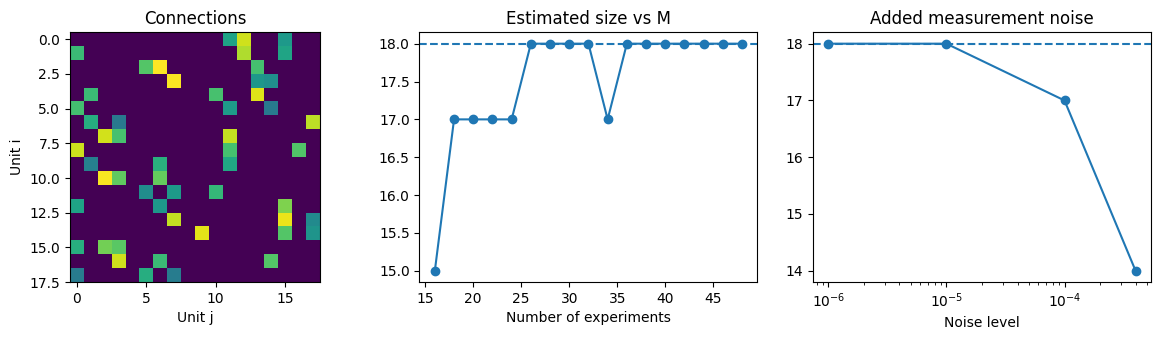

Noise levels: [0, 1e-06, 1e-05, 0.0001, 0.0004]
Estimates:    [18, 18, 18, 17, 14]


In [10]:
m_values = np.arange(n + 4, M + 1, 2)
size_values = [estimate_size(biochemical_trials, m) for m in m_values]
noise_levels = [0, 1e-6, 1e-5, 1e-4, 4e-4]
noise_estimates = []
for noise in noise_levels:
    noisy_data = biochemical_trials + rng.normal(0, noise, biochemical_trials.shape)
    noise_estimates.append(estimate_size(noisy_data, M))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(W)
axes[0].set_title('Connections')
axes[0].set_xlabel('Unit j')
axes[0].set_ylabel('Unit i')
axes[1].plot(m_values, size_values, 'o-')
axes[1].axhline(N, linestyle='--')
axes[1].set_title('Estimated size vs M')
axes[1].set_xlabel('Number of experiments')
axes[2].semilogx(noise_levels[1:], noise_estimates[1:], 'o-')
axes[2].axhline(N, linestyle='--')
axes[2].set_title('Added measurement noise')
axes[2].set_xlabel('Noise level')
plt.tight_layout()
plt.show()
print('Noise levels:', noise_levels)
print('Estimates:   ', noise_estimates)

## 8. Final result and important assumptions

The ideal theory starts with $T=\Theta^{(k)}X_0$ and gives $\mathrm{rank}(T)\leq N$. With sufficiently diverse initial states and full observability through the measured units, $\mathrm{rank}(T)=N$, and then:

$$\boxed{\widehat{N}_{\rm hidden}=\widehat{N}-n}$$

**Important conditions:**

- Use **different, comparable response trials**, not arbitrary overlapping slices of one recording.
- The system must have enough independent initial conditions and observable dynamical directions.
- Nonlinear trials must start sufficiently close in state space for local linearization to work.
- Noise and weak coupling can make the numerical singular-value gap misleading.
- A measured EEG channel is not automatically one physical neuron or network unit.

**What the examples show:** Linear, Kuramoto, Rossler, and Michaelis-Menten simulations can reveal hidden dynamical structure from only part of the network. These plots are small teaching demonstrations, not exact copies of Figures 2-4 or of the authors' numerical results.